# Собираем текстовый корпус

Наша задача - определять автора по фрагменту книги. В обучении будут произведения трёх авторов. Проверять будем на **других произведениях тех же авторов**.

Сначала разберём, как задача определяет структуру данных и проверку. Затем загрузим тексты, сохраним сведения о книгах, нарежем фрагменты и подготовим train/test.

## Сначала задача - потом данные

**Корпус** - тексты и сведения о них. Для **бенчмарка** ещё нужны определённая задача, эталонные ответы, проверочные данные и правила сравнения систем.

> *A benchmark is a standard, test, or point of reference used to measure, evaluate, or compare the performance, quality, or speed of something.*

До загрузки стоит ответить: что система получит на вход, что должна выдать и на каких новых случаях мы хотим её проверить? От этого зависит, что будет одним примером и как хранить разметку.

> CSV удобен для плоской таблицы, JSONL для записей со списками и вложенными полями.

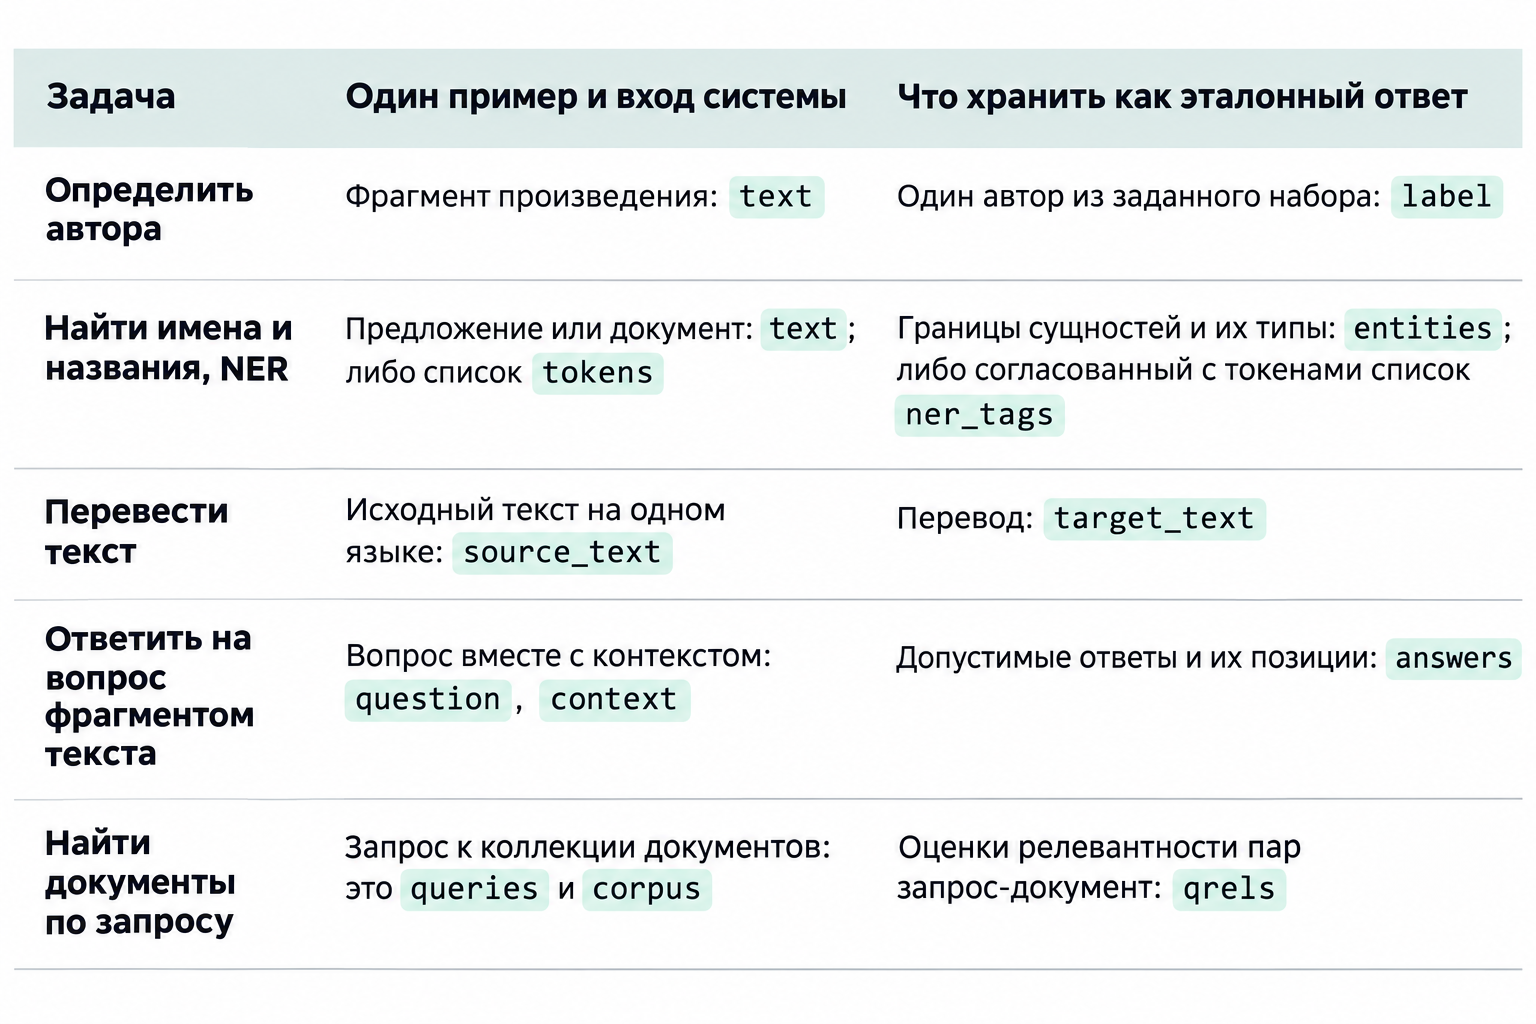

### Один текст, три разные разметки

Возьмём настоящее предложение из *Pride and Prejudice* Джейн Остин, главы 2. Оно есть в файле книги 1342, который загрузим ниже. Метку автора берём из каталога; разметку имён и вопрос ниже составили для этого упражнения.

```python
text = "Mr. Bennet was among the earliest of those who waited on Mr. Bingley."

author_example = {"text": text, "label": "Jane Austen"}

ner_example = {
    "text": text,
    "entities": [
        {"start": 4, "end": 10, "type": "PERSON"}, # Bennet
        {"start": 61, "end": 68, "type": "PERSON"}, # Bingley
    ],
}

qa_example = {
    "context": text,
    "question": "Who did Mr. Bennet visit?",
    "answers": [{"text": "Mr. Bingley", "start": 57}],
}
```

В NER здесь размечаем фамилии, без `Mr.`. Это часть инструкции разметчикам. В QA вопрос входит во **вход**, а ответ - в эталонную разметку. Правильных ответов иногда несколько, поэтому поле допускает список.

Позиции считаются в **символах этой строки**, с нуля, `end` не включается. Например, `text[4:10]` даёт `Bennet`.

> Если после разметки поменять текст, границы могут сдвинуться. Нужно либо размечать окончательную версию, либо хранить связь между версиями и пересчитывать позиции.

### Какие сведения сохранять рядом с текстом?

У полей бывают разные роли:

- **Вход** - то, что будет доступно системе при решении задачи: например, фрагмент книги или вопрос вместе с контекстом.
- **Эталонный ответ** - то, с чем сравниваем предсказание: автор, сущности, перевод. Сохраняем и происхождение ответа: каталог, человеческая разметка, оценка пользователя.
- **Сведения для проверки** - источник, версия текста, дата получения, ID документа и связи с другими примерами. У фрагмента сохраняем ID исходной книги и границы.

Универсального списка метаданных нет. Для проверки на новых товарах нужен `product_id`, на новых пользователях - `user_id`, на будущих текстах - время их появления, а не только дата загрузки. Эти поля стоит собирать сразу: после выгрузки их может быть неоткуда восстановить.

Разметку тоже нужно спроектировать: что означает каждый класс, где начинаются и заканчиваются сущности, какие ответы допустимы. Небольшую пробную разметку полезно проверить до массового сбора, разобрать расхождения и уточнить инструкции. Вместе с корпусом сохраняем правила отбора, разметки и ограничения: какие языки, жанры, периоды и источники представлены.

**Задание 1.** У нас есть фрагменты нескольких книг каждого автора. Сохранены `text`, `book_id` и `author`. Поставлены две задачи:

**А.** Определять автора нового произведения среди уже известных авторов.

**Б.** Находить имена персонажей в произведениях авторов, которых не было в обучении.

Для каждой задачи назовите вход, правильный ответ и поле, по которому нужно разделять данные. Хватает ли имеющейся разметки? Как меняется роль `author`?

### **Разбор**

| | А. Авторство | Б. Поиск имён у новых авторов |
| --- | --- | --- |
| Вход | `text` | `text` |
| Эталон | `author` | Границы имён и тип `PERSON`; эту разметку ещё нужно добавить |
| Разделяем по | `book_id`: произведения разные, авторы представлены в обеих частях | `author`: все тексты одного автора относятся к одной части |
| Роль `author` | Целевой класс | Метаданные и группа для разбиения |

В задаче Б авторы могут быть новыми, потому что система предсказывает сущности, а не автора. В обучающей части тоже размечаем сущности типа `PERSON`. Если бы мы проверяли NER на новых книгах тех же авторов, разделяли бы по книгам. Поле для разбиения выбираем под заявленный сценарий.

### Далее


Дальше реализуем **задачу А**: автор будет ответом, произведение - группой, фрагмент - отдельным примером.

In [ ]:
%pip install -q "pandas>=2.2,<3" "requests>=2.32,<3" "scikit-learn>=1.5,<2"

In [ ]:
from pathlib import Path
import re

import pandas as pd
import requests
from sklearn.model_selection import train_test_split

SEED = 13
pd.set_option("display.max_colwidth", 120)
output_dir = Path("data/authorship")
raw_dir = output_dir / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

##Что будет одной строкой?

Возьмём по три романа Джейн Остин, Артура Конана Дойла и Герберта Уэллса.

Здесь три разных уровня: `author` - кого хотим предсказать; `book_id` - из какого произведения взят текст; `chunk_id` - конкретный фрагмент. Автор и произведение не должны потеряться, когда одна книга превратится в сотни строк.

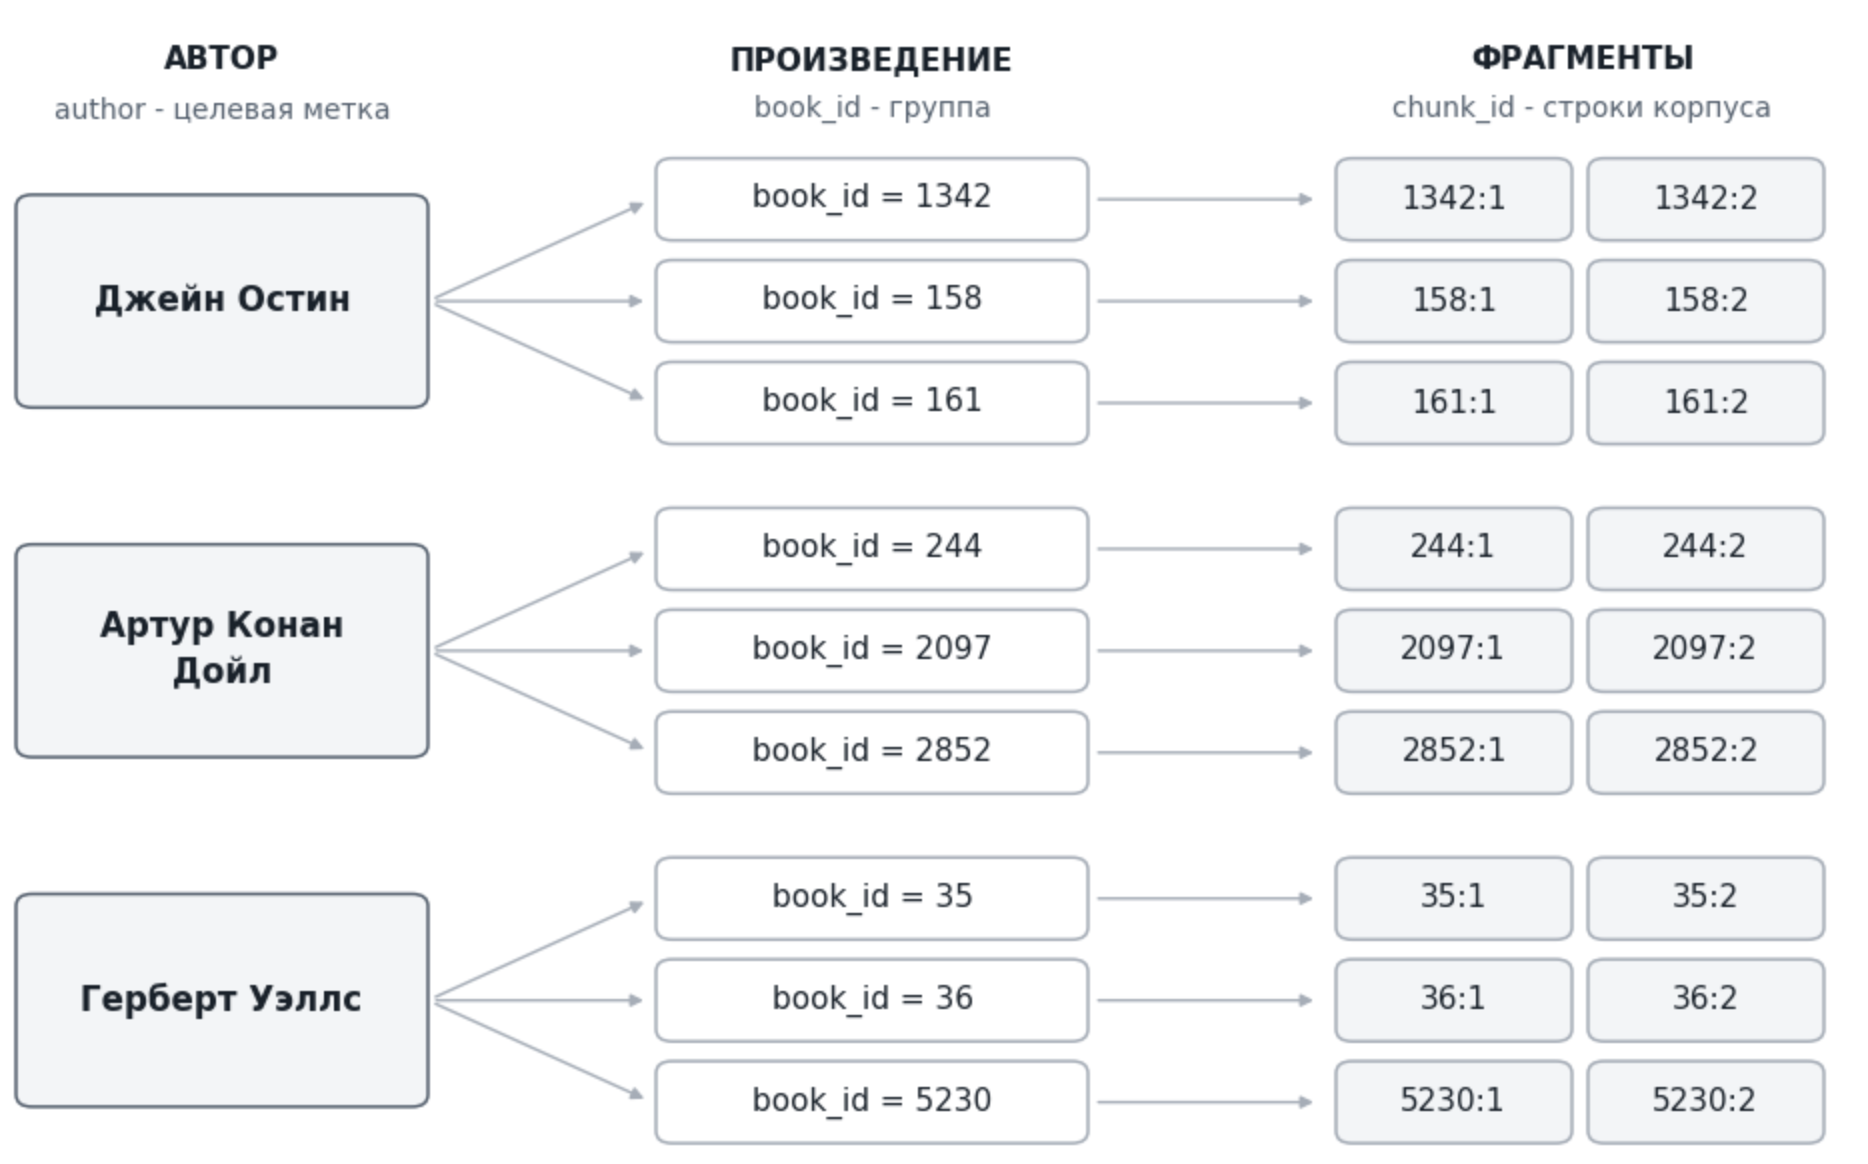

Начнём с каталога. Авторы и названия указаны по карточкам [Project Gutenberg](https://www.gutenberg.org/). Тексты загрузим из [GITenberg](https://github.com/GITenberg), где книги Gutenberg хранятся в Git.

При сборе своего корпуса выбираем авторов, произведения, язык и издания под задачу.

In [ ]:
books = pd.DataFrame(
[   (1342, 'Jane Austen', 'Pride and Prejudice'),
    (158, 'Jane Austen', 'Emma'),
    (161, 'Jane Austen', 'Sense and Sensibility'),
    (244, 'Arthur Conan Doyle', 'A Study in Scarlet'),
    (2097, 'Arthur Conan Doyle', 'The Sign of the Four'),
    (2852, 'Arthur Conan Doyle', 'The Hound of the Baskervilles'),
    (35, 'H. G. Wells', 'The Time Machine'),
    (36, 'H. G. Wells', 'The war of the worlds'),
    (5230, 'H. G. Wells', 'The Invisible Man: A Grotesque Romance')],
    columns=["book_id", "author", "title"],
)
books["language"] = "en"
books["source_url"] = books["book_id"].map(
    lambda book_id: f"https://www.gutenberg.org/ebooks/{book_id}"
)
books[["book_id", "author", "title", "language"]]

,book_id,author,title,language
0,1342,Jane Austen,Pride and Prejudice,en
1,158,Jane Austen,Emma,en
2,161,Jane Austen,Sense and Sensibility,en
3,244,Arthur Conan Doyle,A Study in Scarlet,en
4,2097,Arthur Conan Doyle,The Sign of the Four,en
5,2852,Arthur Conan Doyle,The Hound of the Baskervilles,en
6,35,H. G. Wells,The Time Machine,en
7,36,H. G. Wells,The war of the worlds,en
8,5230,H. G. Wells,The Invisible Man: A Grotesque Romance,en


## 2. Получаем тексты и сохраняем источник

`source_url` ведёт на карточку книги, `download_url` - на конкретный TXT. Сохраним исходные файлы отдельно от обработанного текста.

> Для каждой загрузки записываем `collected_at` - время получения файла. `raise_for_status()` остановит выполнение, если сервер вернул ошибку вместо книги.

In [ ]:
download_urls = {1342: 'https://raw.githubusercontent.com/GITenberg/Pride-and-Prejudice_1342/81db45c9c48c592f0b77f01fc59e677ad0a5634e/1342-0.txt',
 158: 'https://raw.githubusercontent.com/GITenberg/Emma_158/9943f6422b9246e7ad37625d6bd014b035fbfdea/158-0.txt',
 161: 'https://raw.githubusercontent.com/GITenberg/Sense-and-Sensibility_161/1cd7ffed1c21536f6ee2fea4d68c96e2c12ce14c/161.txt',
 244: 'https://raw.githubusercontent.com/GITenberg/A-Study-in-Scarlet_244/28ff9b2f49dad721efd60c4d5ba9645fad84f936/244-0.txt',
 2097: 'https://raw.githubusercontent.com/GITenberg/The-Sign-of-the-Four_2097/c36c6c7a4e7e5f7b8d17c9b19299e8ff996b414c/2097.txt',
 2852: 'https://raw.githubusercontent.com/GITenberg/The-Hound-of-the-Baskervilles_2852/bb11a2bd7e3cda991b7f83936e811a0f472c089c/2852-0.txt',
 35: 'https://raw.githubusercontent.com/GITenberg/The-Time-Machine_35/154a5c628743bd7d35d1af0fc4bcc017f0e111e1/35-0.txt',
 36: 'https://raw.githubusercontent.com/GITenberg/The-War-of-the-Worlds_36/8b08fa3a7cbef117c80b2b437adc46e75c37dbf0/36-0.txt',
 5230: 'https://raw.githubusercontent.com/GITenberg/The-Invisible-Man--A-Grotesque-Romance_5230/ab1e89f8c47a88426460bdfeb6111d82ee408f9a/5230.txt'}
books["download_url"] = books["book_id"].map(download_urls)

In [ ]:
raw_texts = {}
for row in books.itertuples():
    response = requests.get(row.download_url, timeout=30)
    response.raise_for_status()
    path = raw_dir / f"{row.book_id}.txt"
    path.write_bytes(response.content)
    raw_texts[row.book_id] = response.content.decode("utf-8-sig")
    books.loc[row.Index, "raw_path"] = str(path)
    books.loc[row.Index, "collected_at"] = pd.Timestamp.now(tz="UTC").isoformat()

print("Загрузили книг:", len(raw_texts))
print(raw_texts[1342][:1000])

Загрузили книг: 9
The Project Gutenberg EBook of Pride and Prejudice, by Jane Austen

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.org


Title: Pride and Prejudice

Author: Jane Austen

Posting Date: August 26, 2008 [EBook #1342]
Release Date: June, 1998
Last Updated: March 10, 2018

Language: English

Character set encoding: UTF-8

*** START OF THIS PROJECT GUTENBERG EBOOK PRIDE AND PREJUDICE ***




Produced by Anonymous Volunteers





PRIDE AND PREJUDICE

By Jane Austen



Chapter 1


It is a truth universally acknowledged, that a single man in possession
of a good fortune, must be in want of a wife.

However little known the feelings or views of such a man may be on his
first entering a neighbourhood, this truth is so well fixed in the minds
of the surroundi


**Задание 2.** Прочитайте начало скачанного файла. Какие строки написал автор романа, а какие относятся к электронной библиотеке? Что произойдёт, если отправить модели первые 250 слов без проверки?

> **Разбор.** В начале стоят условия использования, название, имя Jane Austen, даты и язык. Это сведения об электронной книге. Если оставить имя автора в признаках, задача частично сведётся к чтению готового ответа. Аналогичная служебная строка с именем автора есть и в конце файла. Поэтому проверяем обе границы, а метаданные сохраняем отдельно от прозы.

### Где начинается само произведение?

Убрать только служебные маркеры Gutenberg недостаточно: внутри могут остаться титульный лист, оглавление, предисловие или примечания редактора.

Для наших девяти файлов границы просмотрены вручную. В `boundaries` записаны начало прозы и первая строка после неё. `index()` находит их позиции, срез включает начало и не включает конец.

In [ ]:
boundaries = {1342: ('It is a truth universally acknowledged, that a single man in possession',
        'End of the Project Gutenberg EBook of Pride and Prejudice, by Jane Austen'),
 158: ('Emma Woodhouse, handsome, clever, and rich, with a comfortable home', 'FINIS'),
 161: ('The family of Dashwood had long been settled in Sussex.', 'THE END'),
 244: ('IN the year 1878 I took my degree of Doctor of Medicine of the', 'ORIGINAL TRANSCRIBER’S NOTES:'),
 2097: ('Sherlock Holmes took his bottle from the corner of the mantel-piece and',
        "End of Project Gutenberg's The Sign of the Four, by Arthur Conan Doyle"),
 2852: ('Mr. Sherlock Holmes, who was usually very late in the mornings, save',
        'End of Project Gutenberg’s The Hound of the Baskervilles, by A. Conan Doyle'),
 35: ('The Time Traveller (for so it will be convenient to speak of him) was',
      'End of the Project Gutenberg EBook of The Time Machine, by H. G. Wells'),
 36: ('No one would have believed in the last years of the nineteenth century',
      'End of the Project Gutenberg EBook of The War of the Worlds, by H. G. Wells'),
 5230: ('The stranger came early in February, one wintry day, through a',
        'End of the Project Gutenberg EBook of The Invisible Man, by H. G. Wells')}

In [ ]:
def extract_body(text, start_marker, end_marker):
    start = text.index(start_marker)
    end = text.index(end_marker, start)
    return text[start:end].strip()

book_texts = {
    book_id: extract_body(text, *boundaries[book_id])
    for book_id, text in raw_texts.items()
}
# в A Study in Scarlet остались ссылки [1], [2], ... на редакторские сноски.
book_texts[244] = re.sub(r"\[\d+\]", "", book_texts[244])

print("НАЧАЛО:\n", book_texts[1342][:550])
print("\nКОНЕЦ:\n", book_texts[1342][-550:])

НАЧАЛО:
 It is a truth universally acknowledged, that a single man in possession
of a good fortune, must be in want of a wife.

However little known the feelings or views of such a man may be on his
first entering a neighbourhood, this truth is so well fixed in the minds
of the surrounding families, that he is considered the rightful property
of some one or other of their daughters.

“My dear Mr. Bennet,” said his lady to him one day, “have you heard that
Netherfield Park is let at last?”

Mr. Bennet replied that he had not.

“But it is,” r

КОНЕЦ:
 n for him, or her curiosity
to see how his wife conducted herself; and she condescended to wait
on them at Pemberley, in spite of that pollution which its woods had
received, not merely from the presence of such a mistress, but the
visits of her uncle and aunt from the city.

With the Gardiners, they were always on the most intimate terms.
Darcy, as well as Elizabeth, really loved them; and they were both ever
sensible of the warmest gratit

## 3. Одна книга - много фрагментов

Возьмём неперекрывающиеся фрагменты по 250 слов. Для длины здесь считаем части после `split()`.

Короткий остаток в конце книги пока отложим и посчитаем, сколько слов не использовали.

Каждая строка наследует `book_id` и `author`. `word_start` и `word_end` - границы в списке после `split()`, правая граница не включается. В тексте фрагмента пробелы и переносы сведены к обычным пробелам.

In [ ]:
CHUNK_WORDS = 250
rows = []
for book in books.itertuples():
    words = book_texts[book.book_id].split()
    for number, start in enumerate(range(0, len(words) - CHUNK_WORDS + 1, CHUNK_WORDS), 1):
        end = start + CHUNK_WORDS
        rows.append((
            f"{book.book_id}:{number}", book.book_id, book.author,
            start, end, " ".join(words[start:end]),
        ))

chunks = pd.DataFrame(rows, columns=[
    "chunk_id", "book_id", "author", "word_start", "word_end", "text",
])
chunks.head(3)

,chunk_id,book_id,author,word_start,word_end,text
0,1342:1,1342,Jane Austen,0,250,"It is a truth universally acknowledged, that a single man in possession of a good fortune, must be in want of a wife..."
1,1342:2,1342,Jane Austen,250,500,single man of large fortune; four or five thousand a year. What a fine thing for our girls!” “How so? How can it aff...
2,1342:3,1342,Jane Austen,500,750,"they visit no newcomers. Indeed you must go, for it will be impossible for _us_ to visit him if you do not.” “You ar..."


In [ ]:
books["n_words"] = books["book_id"].map(lambda key: len(book_texts[key].split()))
books["n_chunks"] = books["n_words"] // CHUNK_WORDS
books["unused_words"] = books["n_words"] % CHUNK_WORDS
display(books[["book_id", "author", "title", "n_words", "n_chunks", "unused_words"]])
print("Фрагментов:", len(chunks))
print("Слов в отложенных остатках:", books["unused_words"].sum())

,book_id,author,title,n_words,n_chunks,unused_words
0,1342,Jane Austen,Pride and Prejudice,121559,486,59
1,158,Jane Austen,Emma,157432,629,182
2,161,Jane Austen,Sense and Sensibility,118553,474,53
3,244,Arthur Conan Doyle,A Study in Scarlet,43267,173,17
4,2097,Arthur Conan Doyle,The Sign of the Four,42995,171,245
5,2852,Arthur Conan Doyle,The Hound of the Baskervilles,59108,236,108
6,35,H. G. Wells,The Time Machine,32374,129,124
7,36,H. G. Wells,The war of the worlds,59870,239,120
8,5230,H. G. Wells,The Invisible Man: A Grotesque Romance,48333,193,83


Фрагментов: 2730
Слов в отложенных остатках: 991


## 4. Как сделать train/test?

Сначала попробуем привычный `train_test_split` на таблице фрагментов. `test_size=1/3` оставит примерно треть строк для проверки. `stratify=chunks["author"]` сохранит в train и test доли авторов, близкие к исходным, `random_state` позволит повторить это разбиение.

> **Но сохранит ли оно независимость произведений?**

In [ ]:
train_rows, test_rows = train_test_split(
    chunks, test_size=1/3, random_state=SEED, stratify=chunks["author"],
)
pd.DataFrame({
    "train": train_rows["author"].value_counts(),
    "test": test_rows["author"].value_counts(),
})

,train,test
author,,
Jane Austen,1059,530
Arthur Conan Doyle,387,193
H. G. Wells,374,187


**Задание 3.** Найдите пересечение `book_id` между `train_rows` и `test_rows`. Есть ли произведения, фрагменты которых оказались в обеих частях?

> Подсказка: `set(...)` превращает значения столбца в множество, а `&` находит пересечение.

In [ ]:
shared_books = set(train_rows["book_id"]) & set(test_rows["book_id"])
print("Общих произведений:", len(shared_books))
books.loc[books["book_id"].isin(shared_books), ["book_id", "author", "title"]]

Общих произведений: 9


,book_id,author,title
0,1342,Jane Austen,Pride and Prejudice
1,158,Jane Austen,Emma
2,161,Jane Austen,Sense and Sensibility
3,244,Arthur Conan Doyle,A Study in Scarlet
4,2097,Arthur Conan Doyle,The Sign of the Four
5,2852,Arthur Conan Doyle,The Hound of the Baskervilles
6,35,H. G. Wells,The Time Machine
7,36,H. G. Wells,The war of the worlds
8,5230,H. G. Wells,The Invisible Man: A Grotesque Romance


**Разбор.** В обеих частях оказались все девять произведений. Строки разные, но модель увидела бы другие фрагменты тех же книг. Персонажи, события и характерная лексика могут помочь узнавать знакомое произведение. Такой тест отвечает на вопрос о новых фрагментах знакомых книг. Мы хотели проверить другую ситуацию: произведение целиком не встречалось в обучении.

### Разделим произведения, затем назначим split фрагментам

В каталоге одна строка соответствует одной книге. Разобьём **каталог**, сохраняя авторов в обеих частях: для каждого получатся две книги в train и одна в test. Все фрагменты книги унаследуют одно назначение.

Здесь `stratify=books["author"]` управляет составом **книг**. Он не обещает точного баланса числа фрагментов: романы разной длины.

In [ ]:
train_books, test_books = train_test_split(
    books, test_size=3, random_state=SEED, stratify=books["author"],
)
books["split"] = "train"
books.loc[test_books.index, "split"] = "test"
chunks["split"] = chunks["book_id"].map(books.set_index("book_id")["split"])

pd.crosstab(books["author"], books["split"])[["train", "test"]]

split,train,test
author,,
Arthur Conan Doyle,2,1
H. G. Wells,2,1
Jane Austen,2,1


In [ ]:
train = chunks.loc[chunks["split"].eq("train")]
test = chunks.loc[chunks["split"].eq("test")]
print("Общие книги:", set(train["book_id"]) & set(test["book_id"]))
print("Авторы в train:", sorted(train["author"].unique()))
print("Авторы в test:", sorted(test["author"].unique()))
pd.crosstab(chunks["book_id"], chunks["split"])[["train", "test"]]

Общие книги: set()
Авторы в train: ['Arthur Conan Doyle', 'H. G. Wells', 'Jane Austen']
Авторы в test: ['Arthur Conan Doyle', 'H. G. Wells', 'Jane Austen']


split,train,test
book_id,,
35,129,0
36,239,0
158,629,0
161,0,474
244,173,0
1342,486,0
2097,171,0
2852,0,236
5230,0,193


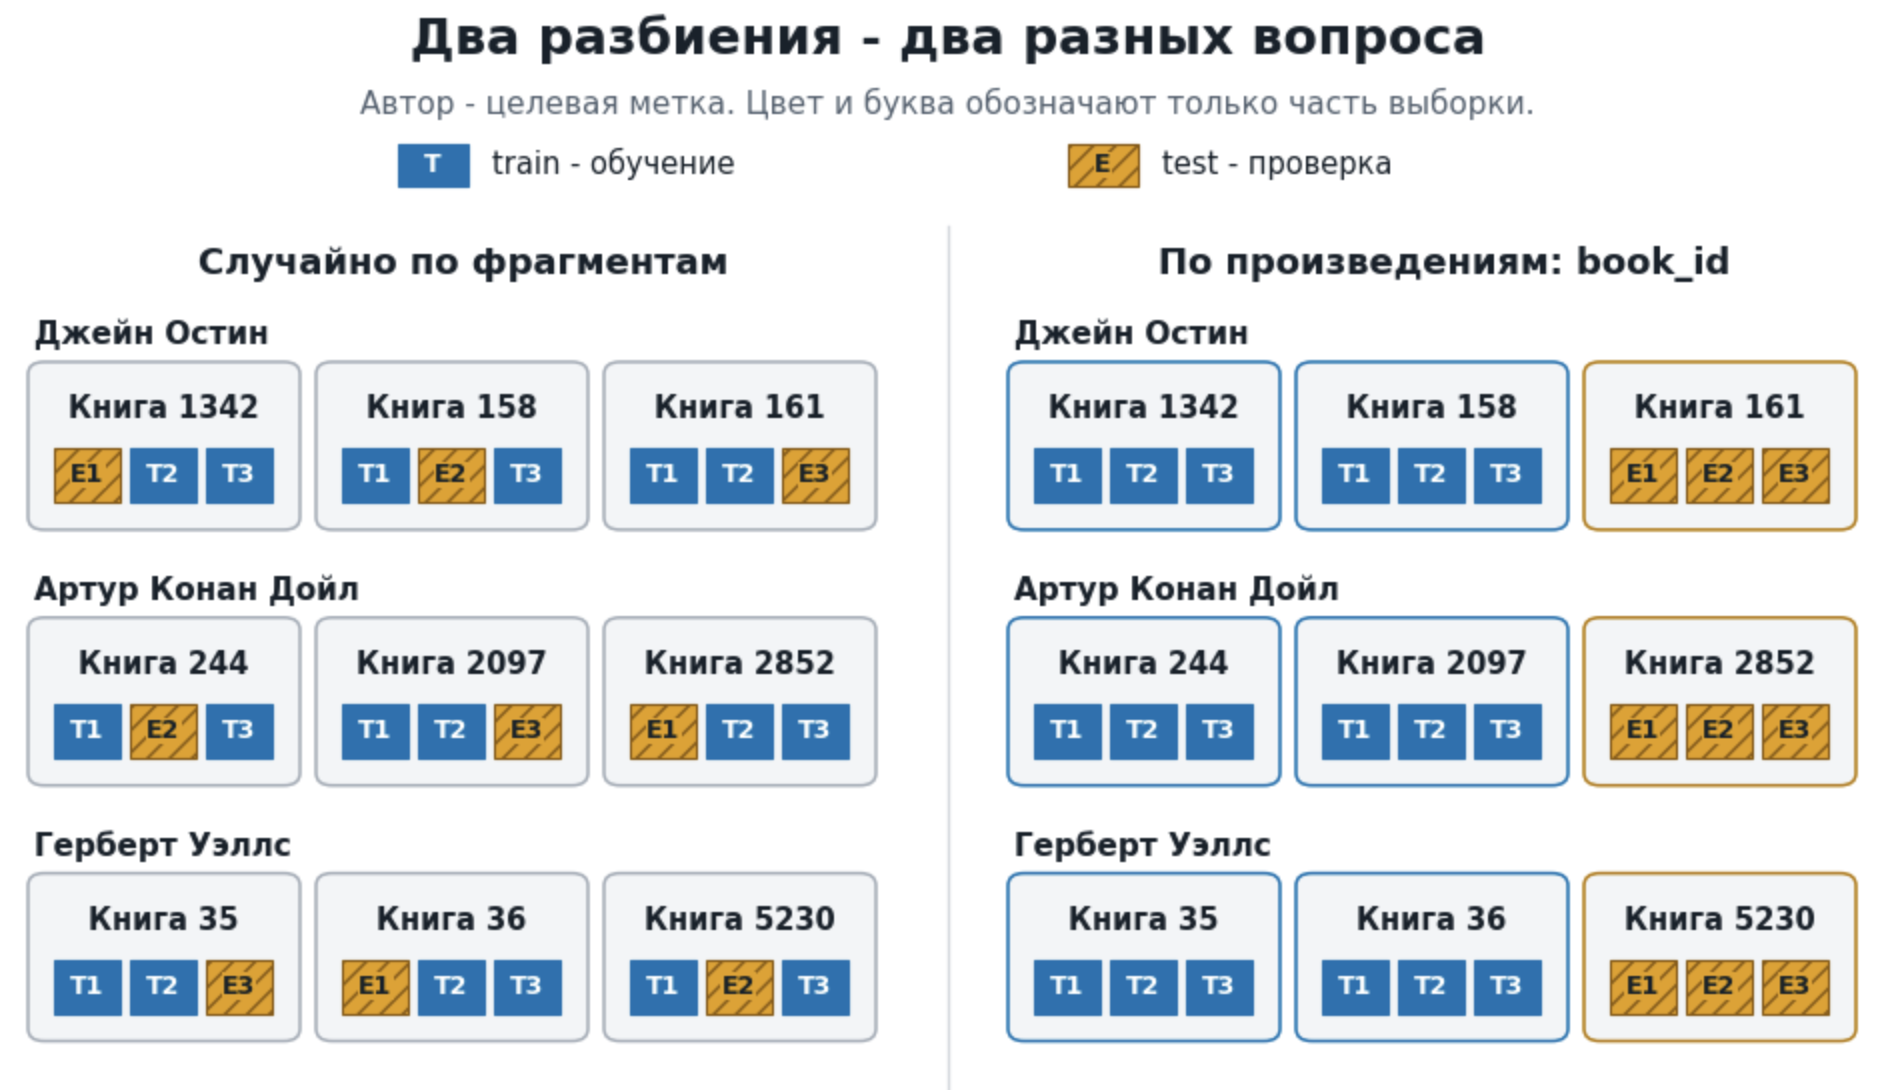

## 5. Сохраняем корпус

Сохраним каталог, фрагменты и отдельно назначение книг в train/test. В `raw/` уже лежат исходные файлы. Дальше можно прочитать таблицы обычным `pd.read_csv` и продолжить работу.

Для будущей модели входом станет `text`, ответом - `author`. Названия книг, URL и идентификаторы оставляем для проверки данных и воспроизводимости.

In [ ]:
books.to_csv(output_dir / "books.csv", index=False)
chunks.to_csv(output_dir / "chunks.csv", index=False)
books[["book_id", "author", "split"]].to_csv(output_dir / "book_split.csv", index=False)
print("Сохранили в:", output_dir)

Сохранили в: data/authorship


### Что ещё зафиксировать для бенчмарка?

Теперь есть данные и разбиение.

| Решение | Для нашей задачи авторства |
| --- | --- |
| Сценарий | Новый фрагмент из произведения, которого не было в обучении, автор входит в известную тройку |
| Вход и ответ | На вход подаём только `text`, предсказываем `author`. Название книги, ID и авторская подпись не входят в признаки |
| Эталон | Автор по каталогу, фиксируем те же версии текстов и правила нарезки |
| Разбиение | Используем сохранённый `book_split.csv`. Для выбора настроек выделяем validation по книгам внутри train |
| Основная метрика | Например, macro-F1 по фрагментам: сначала F1 каждого автора, затем среднее по трём авторам |
| Проверка результата | Дополнительно смотрим результат по каждому автору и произведению, test не используем для выбора настроек |


> Macro-F1 даёт одинаковый вес авторам, но не отдельным произведениям. Фрагменты одной книги при этом не становятся независимыми произведениями. Общая accuracy по фрагментам сильнее учитывает длинные книги. Поэтому нужно явно записать не только название метрики, но и **что оцениваем и как усредняем**.

Для NER можно считать F1 по сущностям с верными границами и типом; для извлекаемых ответов - точное совпадение или совпадение слов ответа, для поиска документов - качество ранжирования. Это разные правила сравнения.


### Что мы в итоге подготовили?

Небольшой корпус для проверки на новых произведениях трёх известных авторов. У каждой строки есть происхождение, у каждой книги - назначенная часть выборки.

Пару вещей стоит помнить:

- Автор связан с жанром, эпохой и персонажами. Холмс появляется в разных книгах Дойла. Даже высокая точность будущей модели не докажет, что она выделила именно авторский стиль.
- Для подбора модели понадобится validation или проверка по группам внутри train. Отложенные произведения test не используем для выбора настроек.